Neuron Model

In [50]:
class Neuron:
    def __init__(self, resting_potential=-70, threshold=-55,
                 current_potential=-70, neuron_type="excitatory"):

        self.resting_potential = resting_potential
        self.threshold = threshold
        self.current_potential = current_potential
        self.connected_neuron = None
        self.neuron_type = neuron_type

    def receive_stimulus(self):
        stimulus = int(input("Enter the stimulus: "))
        self.current_potential += stimulus
        self.fire()

    def fire(self):
        if self.current_potential >= self.threshold:
            print("Fire!")
        else:
            print("The stimulus is below threshold value. No Action Potential generated!")

    def reset(self):
        self.current_potential = self.resting_potential
        print("Reset")

    def connect_to(self, neuron):
        self.connected_neuron = neuron
        print("Neuron connected!")

    def send_signal(self, signal):
        if self.connected_neuron is not None:

            if self.neuron_type == "excitatory":
                self.connected_neuron.current_potential += signal

            elif self.neuron_type == "inhibitory":
                self.connected_neuron.current_potential -= signal

            print("Signal sent!")
            self.connected_neuron.fire()

            if self.connected_neuron.connected_neuron is not None:
                self.connected_neuron.send_signal(signal)

In [ ]:
#Creating an Object
neuron=Neuron()
neuron.receive_stimulus()

Enter the stimulus:45
Fire!


In [ ]:
neuron=Neuron()
neuron.fire()

The stimulus is below threshold value.No Action Potential generated!


In [ ]:
neuron=Neuron()
neuron.reset()

Reset


Action-Potential

[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100]


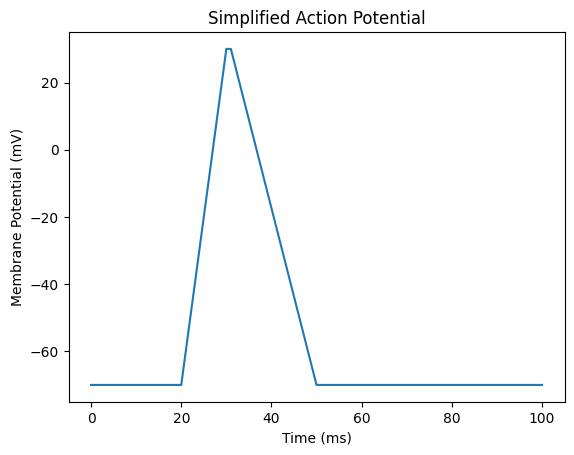

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
time = np.arange(0, 101, 1)
print(time)
potential = np.full(len(time), -70.0)
potential[20:31] = np.linspace(-70, 30, 11)
potential[31:51] = np.linspace(30, -70, 20)
potential[51:] = -70
plt.plot(time, potential)
plt.xlabel("Time (ms)")
plt.ylabel("Membrane Potential (mV)")
plt.title("Simplified Action Potential")
plt.show()

Multiple Neurons

In [ ]:
neuron1=Neuron()
neuron1.receive_stimulus()
neuron2=Neuron()
neuron2.receive_stimulus()
neuron3=Neuron()
neuron3.receive_stimulus()

Enter the stimulus:4
The stimulus is below threshold value.No Action Potential generated!
Enter the stimulus:78
Fire!
Enter the stimulus:90
Fire!


In [ ]:
neurons = [Neuron(), Neuron(), Neuron()]
print(len(neurons))
for neuron in neurons:
    neuron.receive_stimulus()

3
Enter the stimulus:23
Fire!
Enter the stimulus:1
The stimulus is below threshold value.No Action Potential generated!
Enter the stimulus:70
Fire!


Neuron Connections

In [ ]:
neuron1 = Neuron()
neuron2 = Neuron()
neuron3 = Neuron()
neuron4 = Neuron()
neuron5=Neuron()
neuron1.connect_to(neuron2)
neuron2.connect_to(neuron3)
neuron3.connect_to(neuron4)
neuron4.connect_to(neuron5)

Neuron connected!
Neuron connected!
Neuron connected!
Neuron connected!


In [ ]:
neuron1.connect_to(neuron2)
neuron1.send_signal()
print("Neuron 2 potential:", neuron2.current_potential)

Neuron connected!
Enter the stimulus:78
Signal sent!
Fire!
Neuron 2 potential: 53


In [ ]:
neuron1.send_signal()

Enter the stimulus: 34
Signal sent!
Fire!
Enter the stimulus: 67
Signal sent!
Fire!
Enter the stimulus: 1
Signal sent!
The stimulus is below threshold value.No Action Potential generated!


In [ ]:
print("Neuron 1:", neuron1.current_potential)
print("Neuron 2:", neuron2.current_potential)
print("Neuron 3:", neuron3.current_potential)
print("Neuron 4:", neuron4.current_potential)

Neuron 1: -70
Neuron 2: -36
Neuron 3: -3
Neuron 4: -69


Excitatory & Inhibitory Neurons

In [ ]:
neuron1=Neuron(neuron_type="excitatory")
neuron2=Neuron()
neuron1.connect_to(neuron2)
neuron1.send_signal()
print("Neuron 2 potential:",neuron2.current_potential)

Neuron connected!
Enter the stimulus: 67
Signal sent!
Fire!
Signal sent!
Fire!
Neuron 2 potential: -3


In [ ]:
neuron3 = Neuron(neuron_type="inhibitory")
neuron4 = Neuron()
neuron3.connect_to(neuron4)
neuron3.send_signal()
print("Neuron 4 potential:", neuron4.current_potential)

Neuron connected!
Enter the stimulus: 10
Signal sent!
The stimulus is below threshold value.No Action Potential generated!
Signal sent!
The stimulus is below threshold value.No Action Potential generated!
Neuron 4 potential: -80


In [5]:
excitatory_neuron = Neuron(neuron_type="excitatory")
inhibitory_neuron = Neuron(neuron_type="inhibitory")
target_neuron = Neuron()
excitatory_neuron.connect_to(target_neuron)
inhibitory_neuron.connect_to(target_neuron)
excitatory_neuron.send_signal()
print("After excitatory signal:", target_neuron.current_potential)
target_neuron.reset()
inhibitory_neuron.send_signal()
print("After inhibitory signal:", target_neuron.current_potential)

Neuron connected!
Neuron connected!
Enter the stimulus: 34
Signal sent!
Fire!
After excitatory signal: -36
Reset
Enter the stimulus: 90
Signal sent!
The stimulus is below threshold value.No Action Potential generated!
After inhibitory signal: -160


Neural Network Simulation

In [3]:
network = [
    Neuron(neuron_type="excitatory"),
    Neuron(neuron_type="excitatory"),
    Neuron(neuron_type="inhibitory"),
    Neuron(neuron_type="excitatory"),
    Neuron(neuron_type="inhibitory")
]
print(len(network))
for neuron in network:
    print(neuron.neuron_type)

5
excitatory
excitatory
inhibitory
excitatory
inhibitory


In [4]:
for i in range(len(network) - 1):
    network[i].connect_to(network[i + 1])
network[0].send_signal()

Neuron connected!
Neuron connected!
Neuron connected!
Neuron connected!
Enter the stimulus: 45
Signal sent!
Fire!


Experiments

In [18]:
#Different stimulus strength
#Small sTimulus
neuron1=Neuron()
neuron1.receive_stimulus()
neuron1.reset()
#Medium Stimulus
neuron2=Neuron()
neuron2.receive_stimulus()
neuron2.reset()
#Large Stimulus
neuron3=Neuron()
neuron3.receive_stimulus()

Enter the stimulus:1
The stimulus is below threshold value.No Action Potential generated!
Reset
Enter the stimulus:15
Fire!
Reset
Enter the stimulus:90
Fire!


In [27]:
#Excitatory & Inhibitory
neuron1 = Neuron(neuron_type="excitatory")
neuron2 = Neuron(neuron_type="inhibitory")
neuron3 = Neuron(neuron_type="inhibitory")
neuron1.connect_to(neuron2)
neuron2.connect_to(neuron3)

neuron1.send_signal()
print(neuron2.current_potential)

neuron2.send_signal()
print(neuron3.current_potential)

Neuron connected!
Neuron connected!
Enter the stimulus: 78
Signal sent!
Fire!
8
Enter the stimulus: 78
Signal sent!
The stimulus is below threshold value.No Action Potential generated!
-148


In [51]:
#All Excitatory

network1 = [
    Neuron(neuron_type="excitatory"),
    Neuron(neuron_type="excitatory"),
    Neuron(neuron_type="excitatory"),
    Neuron(neuron_type="excitatory"),
    Neuron(neuron_type="excitatory")
]

for i in range(len(network1) - 1):
    network1[i].connect_to(network1[i + 1])

network1[0].send_signal(10)

for neuron in network1:
    print(neuron.current_potential)

Neuron connected!
Neuron connected!
Neuron connected!
Neuron connected!
Signal sent!
The stimulus is below threshold value. No Action Potential generated!
Signal sent!
The stimulus is below threshold value. No Action Potential generated!
Signal sent!
The stimulus is below threshold value. No Action Potential generated!
Signal sent!
The stimulus is below threshold value. No Action Potential generated!
-70
-60
-60
-60
-60


In [52]:
#Excitatory & Inhibitory Network
network2 = [
    Neuron(neuron_type="excitatory"),
    Neuron(neuron_type="inhibitory"),
    Neuron(neuron_type="excitatory"),
    Neuron(neuron_type="inhibitory"),
    Neuron(neuron_type="excitatory")
]

for i in range(len(network2) - 1):
    network2[i].connect_to(network2[i + 1])

network2[0].send_signal(10)

for neuron in network2:
    print(neuron.current_potential)

Neuron connected!
Neuron connected!
Neuron connected!
Neuron connected!
Signal sent!
The stimulus is below threshold value. No Action Potential generated!
Signal sent!
The stimulus is below threshold value. No Action Potential generated!
Signal sent!
The stimulus is below threshold value. No Action Potential generated!
Signal sent!
The stimulus is below threshold value. No Action Potential generated!
-70
-60
-80
-60
-80


Data Analysis

In [64]:
import pandas as pd
neuron = pd.Series(["N1", "N2", "N3", "N4", "N5"])
all_excitatory = pd.Series([-70, -60, -60, -60, -60])
mixed_network = pd.Series([-70, -60, -80, -60, -80])
df=pd.DataFrame({"Neuron":neuron, "Excitatory Network":all_excitatory, "Mixed Network":mixed_network})
print(df)

  Neuron  Excitatory Network  Mixed Network
0     N1                 -70            -70
1     N2                 -60            -60
2     N3                 -60            -80
3     N4                 -60            -60
4     N5                 -60            -80


In [57]:
import numpy as np
import pandas as pd
print(df["Excitatory Network"].mean())
print(df["Mixed Network"].min())
print(df["Mixed Network"].max())

-62.0
-80
-60


In [58]:
print("Range:", df["Mixed Network"].max() - df["Mixed Network"].min())

Range: 20


In [59]:
print("Variance:", df["Mixed Network"].var())

Variance: 100.0


In [60]:
print("Standard Deviation:", df["Mixed Network"].std())

Standard Deviation: 10.0


Visualization

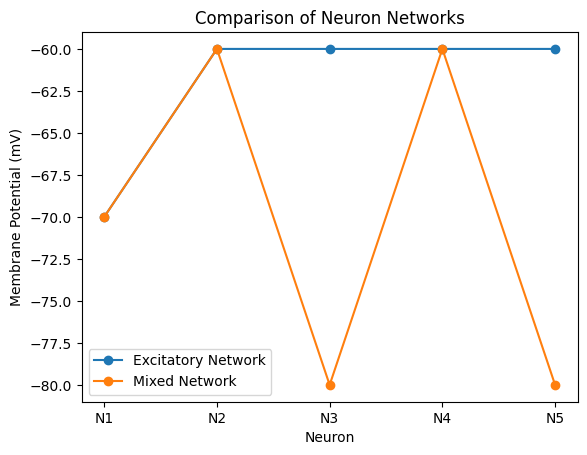

In [65]:
import matplotlib.pyplot as plt
plt.plot(df["Neuron"], df["Excitatory Network"], marker="o", label="Excitatory Network")
plt.plot(df["Neuron"], df["Mixed Network"], marker="o", label="Mixed Network")

plt.xlabel("Neuron")
plt.ylabel("Membrane Potential (mV)")
plt.title("Comparison of Neuron Networks")

plt.legend()
plt.show()

In [66]:
n = int(input("Enter number of neurons: "))

network = []

for i in range(n):
    neuron_type = input(f"Enter type for Neuron {i+1} (excitatory/inhibitory): ")
    network.append(Neuron(neuron_type=neuron_type))

for i in range(n - 1):
    network[i].connect_to(network[i + 1])

signal = int(input("Enter signal strength: "))

network[0].send_signal(signal)

print("\nFinal membrane potentials:")

for i in range(n):
    print(f"Neuron {i+1}: {network[i].current_potential} mV")

Enter number of neurons: 6
Enter type for Neuron 1 (excitatory/inhibitory): excitatory
Enter type for Neuron 2 (excitatory/inhibitory): inhibitory
Enter type for Neuron 3 (excitatory/inhibitory): inhibitory
Enter type for Neuron 4 (excitatory/inhibitory): excitatory
Enter type for Neuron 5 (excitatory/inhibitory): excitatory
Enter type for Neuron 6 (excitatory/inhibitory): inhibitory
Neuron connected!
Neuron connected!
Neuron connected!
Neuron connected!
Neuron connected!
Enter signal strength: 67
Signal sent!
Fire!
Signal sent!
The stimulus is below threshold value. No Action Potential generated!
Signal sent!
The stimulus is below threshold value. No Action Potential generated!
Signal sent!
Fire!
Signal sent!
Fire!

Final membrane potentials:
Neuron 1: -70 mV
Neuron 2: -3 mV
Neuron 3: -137 mV
Neuron 4: -137 mV
Neuron 5: -3 mV
Neuron 6: -3 mV
